# 03 Neo4j: the revert graph and Cypher Q1-Q5

| | |
|---|---|
| **Question** | Who reverts whom, and what editor and page structures go with edit wars (spec section 4)? |
| **Answer** | <!--fact:cypher_q1_mutual_pairs-->462<!--/fact--> mutual-revert pairs on <!--fact:cypher_q1_pages-->397<!--/fact--> pages; <!--fact:top20_mutual_pairs-->51<!--/fact--> of them (<!--fact:top20_mutual_pairs_pct-->11.04<!--/fact-->%) are on the top 20 contested pages. The editor who reverts the most (by degree) is <!--fact:cypher_q2_top_by_degree_editor-->ClueBot NG<!--/fact-->; the highest PageRank is <!--fact:cypher_q2_top_pagerank_editor-->ClueBot NG<!--/fact-->. Only <!--fact:cypher_q3_communities_2plus-->1,191<!--/fact--> Louvain communities have 2 or more editors. The largest (<!--fact:cypher_q3_largest_community_editors-->564<!--/fact--> editors) is mostly one reverter and the editors it reverted: <!--fact:cypher_q3_largest_community_star_share_pct-->69.1<!--/fact-->% of its revert relationships touch <!--fact:cypher_q3_largest_community_top_reverter-->ClueBot NG<!--/fact-->. |
| **Time to run** | about 10 seconds |
| **Needs** | the local Neo4j loaded by `load_neo4j.py` (Docker, with GDS). Neo4j Desktop works too (see README, way 2). |

Human editors appear only as pseudonyms (`editor_` + 10 hex digits). Bots keep their names. All data times are UTC. Words: see `GLOSSARY.md`. Numbers: see `report/FACTS.md`. Every number in the text comes from there (`report/sync_notebook_text.py` copies it).

## Setup

**What:** Finds the project folder, imports `config.py` and the report helpers, and prints the data version.

**Why:** Every rule and path comes from `config.py`. The data version tells you which data release you have.

**You should see:** `DATA_VERSION: data-v1` (or a later version) and the path of the Python program.

In [1]:
# Set up the paths: this notebook is in ec-hw2/notebooks/, the project code is in ec-hw2/.
import sys, time, json
from pathlib import Path
HW2 = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd() / "ec-hw2"
sys.path.insert(0, str(HW2))
import config
import pandas as pd
from tabulate import tabulate
from IPython.display import Image, Markdown, display
from report import build_facts as facts      # FACTS.md helpers (check, tables with pseudonyms)
from report import make_figures as figs      # the report charts
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)
T0 = time.time()

def _cell(v):
    if v is None or v is pd.NA or (isinstance(v, float) and v != v):
        return ""
    if isinstance(v, float):
        return f"{v:,.1f}" if abs(v) >= 1000 else f"{v:.4g}"
    return v

def show(df, n=None):
    """Print a table as text (it reads well on GitHub). Each cell keeps its own type."""
    d = df if n is None else df.head(n)
    rows = [[_cell(v) for v in r] for r in d.astype(object).itertuples(index=False)]
    print(tabulate(rows, headers=list(d.columns), tablefmt="github"))

print("DATA_VERSION:", config.DATA_VERSION)
print("Python:", sys.executable)

DATA_VERSION: data-v2
Python: /Users/scottnelson/Desktop/226/truth-lag/.venv/bin/python3


## 1. Connect

**What:** Connects to Neo4j and defines `run_cypher_file()`, which prints a file from `queries/cypher/` and runs its statements with `queries/run_cypher.py`. Every result is checked: an editor column may only show an alias or a bot name.

**Why:** The notebook runs exactly the query files; it types no query itself.

**You should see:** `connected to the local Neo4j, version 2026.10.1` (the password is never printed).

In [2]:
from neo4j import GraphDatabase
import load_neo4j
from queries import run_cypher
driver = GraphDatabase.driver(config.NEO4J_URI, auth=(config.NEO4J_USER, config.NEO4J_PASSWORD))
driver.verify_connectivity()
session = driver.session()
version = session.run("CALL dbms.components() YIELD name, versions WHERE name = 'Neo4j Kernel' "
                      "RETURN versions[0] AS v").single()["v"]
print("connected to the local Neo4j, version", version)
allowed = set(session.run("MATCH (e:Editor) RETURN collect(e.alias) AS a").single()["a"])   # aliases + bot names
CDIR = HW2 / "queries" / "cypher"
times = {}

def run_cypher_file(name, print_code=True):
    """Print the statements of queries/cypher/<name>.cypher, run them in order, return the result tables."""
    q = run_cypher.parse_file(CDIR / f"{name}.cypher")
    frames = {}
    for i, st in enumerate(q["statements"], start=1):
        if print_code:
            print(f"// statement {i}" + (f"  (result: {st['label']})" if st["label"] else ""))
            print(st["code"].strip() + ";\n")
        keys, rows, ms = run_cypher.run_once(session, st["code"])
        if st["label"]:
            df = pd.DataFrame(rows, columns=keys)
            run_cypher.check_privacy(df, allowed, f"{name} {st['label']}")   # stops if a name is not an alias
            frames[st["label"]] = df
            times[(name, st["label"])] = round(ms, 1)
    print(f"-> results: {', '.join(f'{k} ({len(v)} rows)' for k, v in frames.items())}\n")
    return frames

connected to the local Neo4j, version 2026.10.1


## 2. The graph model

**What:** Shows the graph model: node and relationship counts, and the property names of each label and type.

**Why:** This is the model part of the Neo4j section: `(:Editor)-[:EDITED]->(:Page)` and `(:Editor)-[:REVERTED]->(:Editor)`, built from the history cohort. On EDITED, `reverted` means reverted within 20 days, but `reverted_by_other` and `reverting_rev_id` mean reverted at any time before the snapshot. So the queries always add `within_followup`.

**You should see:** Editor <!--fact:neo4j_editor_count-->37,546<!--/fact-->, Page <!--fact:neo4j_page_count-->165,415<!--/fact-->, EDITED <!--fact:neo4j_edited_count-->295,013<!--/fact-->, REVERTED <!--fact:neo4j_reverted_count-->13,269<!--/fact-->, contested pages <!--fact:contested_pages_total-->126<!--/fact-->. REVERTED has `page_id`, `count`, `n_revisions`, `ts`, `last_ts`.

In [3]:
counts = load_neo4j.graph_counts(session)
show(pd.DataFrame([{"what": k, "count": v} for k, v in counts.items()]))
print()
for label in ("Editor", "Page"):
    keys = session.run(f"MATCH (n:{label}) WITH n LIMIT 1 RETURN keys(n) AS k").single()["k"]
    print(f"(:{label}) properties: {', '.join(sorted(keys))}")
for rel in ("EDITED", "REVERTED"):
    keys = session.run(f"MATCH ()-[r:{rel}]->() WITH r LIMIT 1 RETURN keys(r) AS k").single()["k"]
    print(f"[:{rel}] properties: {', '.join(sorted(keys))}")
ex = session.run("MATCH (a:Editor)-[r:REVERTED]->(b:Editor) WHERE a.kind = 'bot' "
                 "RETURN a.alias AS reverter, b.alias AS reverted, r.page_id AS page_id, r.count AS count "
                 "ORDER BY r.count DESC, page_id LIMIT 3").data()
print("\nExample REVERTED relationships (aliases):")
show(pd.DataFrame(ex))

| what           |   count |
|----------------|---------|
| Editor         |   37546 |
| Page           |  165415 |
| EDITED         |  295013 |
| REVERTED       |   13269 |
| contested Page |     126 |

(:Editor) properties: alias, communityId, edits, key, kind, reverts_made, reverts_received
(:Page) properties: contested, edits, id, revert_actions, reverted_editors, title


[:EDITED] properties: rev_id, reverted, reverted_by_other, ts, within_followup
[:REVERTED] properties: count, last_ts, n_revisions, page_id, ts

Example REVERTED relationships (aliases):
| reverter   | reverted          |   page_id |   count |
|------------|-------------------|-----------|---------|
| ClueBot NG | editor_f620b7caa7 |   7813222 |       2 |
| ClueBot NG | editor_3c6d7b5517 |       791 |       1 |
| ClueBot NG | editor_177627cf97 |       894 |       1 |


## 3. Cypher Q1: mutual reverts

**What:** Cypher Q1: mutual-revert pairs on the same page, `(a)-[:REVERTED]->(b)-[:REVERTED]->(a)` with the same `page_id`; each pair once (a.key < b.key).

**Why:** Spec 4.1 (edit wars), and the 'mutual reverts' question of the comparison (notebook 04).

**You should see:** <!--fact:cypher_q1_mutual_pairs-->462<!--/fact--> pairs on <!--fact:cypher_q1_pages-->397<!--/fact--> pages, <!--fact:cypher_q1_editors-->631<!--/fact--> editors, <!--fact:cypher_q1_pairs_with_bot-->25<!--/fact--> pairs with a bot.

In [4]:
r1 = run_cypher_file("q1_mutual_reverts")
show(r1["main"], 10)
print()
show(r1["total"])
tot = r1["total"].iloc[0]
q2_top = pd.read_csv(config.RESULTS_DIR / "mongo_q2_top_contested_pages.csv")["page_id"]
on_top = r1["main"][r1["main"]["page_id"].isin(q2_top)]
print(f"\nFacts: {tot['mutual_pairs']} editor pairs reverted each other on the same page, on {tot['pages']} pages. "
      f"{len(on_top)} of these pairs ({100 * len(on_top) / tot['mutual_pairs']:.1f}%) are on the top 20 contested pages "
      f"of Mongo Q2, which are 20 of {counts['Page']:,} pages.")

// statement 1  (result: main)
MATCH (a:Editor)-[r1:REVERTED]->(b:Editor)-[r2:REVERTED]->(a)
WHERE r1.page_id = r2.page_id AND a.key < b.key
MATCH (p:Page {id: r1.page_id})
RETURN p.id AS page_id, p.title AS page_title, a.alias AS editor_a, b.alias AS editor_b,
       r1.count AS a_reverted_b, r2.count AS b_reverted_a
ORDER BY page_id, a.key, b.key;



// statement 2  (result: total)
MATCH (a:Editor)-[r1:REVERTED]->(b:Editor)-[r2:REVERTED]->(a)
WHERE r1.page_id = r2.page_id AND a.key < b.key
WITH count(*) AS mutual_pairs, count(DISTINCT r1.page_id) AS pages,
     count(CASE WHEN a.kind = 'bot' OR b.kind = 'bot' THEN 1 END) AS pairs_with_bot,
     collect(a) + collect(b) AS people
UNWIND people AS e
RETURN mutual_pairs, pages, count(DISTINCT e) AS editors, pairs_with_bot;



-> results: main (462 rows), total (1 rows)

|   page_id | page_title                            | editor_a          | editor_b          |   a_reverted_b |   b_reverted_a |
|-----------|---------------------------------------|-------------------|-------------------|----------------|----------------|
|      1921 | Al-Qaeda                              | editor_9eb8ef10a7 | editor_0d0cfcfbf9 |              1 |              1 |
|      6443 | Ceuta                                 | editor_36d2f02780 | editor_3b58b3c064 |              1 |              2 |
|      8691 | Divination                            | editor_37519a19ee | editor_2a2c1d5e4e |              1 |              2 |
|     11642 | General_Dynamics_F-16_Fighting_Falcon | editor_87b8cee2d3 | editor_6ce3a652ad |              1 |              1 |
|     12861 | Governor_of_New_York                  | editor_47e86b5cd9 | editor_487db86817 |              1 |              1 |
|     14653 | Iran                                  | edito

## 4. Cypher Q2: central reverters

**What:** Cypher Q2 gives two lists, and they answer two different questions.
- `by_degree` counts the REVERTED relationships that go out of each editor. It answers "who reverts the most".
- PageRank (GDS) runs on the REVERSE projection (weight = count), so the score flows to the editor who reverts. A high score means "reverts editors who are themselves active reverters". It does not mean "reverts a lot". Both PageRank calls run until they converge (maxIterations 200, tolerance 1e-7).

**Why:** Spec 4.2. Use `by_degree` for "who reverts the most". Use PageRank only with the meaning above.

**You should see:**
- By degree, rank 1 is <!--fact:cypher_q2_top_by_degree_editor-->`ClueBot NG`<!--/fact--> with <!--fact:cypher_q2_top_by_degree_out_degree-->591<!--/fact--> REVERTED relationships out and <!--fact:cypher_q2_top_by_degree_reverts_made-->592<!--/fact--> revert actions.
- By PageRank, rank 1 is <!--fact:cypher_q2_top_pagerank_editor-->`ClueBot NG`<!--/fact--> (score <!--fact:cypher_q2_top_pagerank-->87.58<!--/fact-->, converged after <!--fact:cypher_q2_pagerank_iterations-->111<!--/fact--> iterations). Most of the others are registered users, shown as aliases.
- The PageRank top 20 also holds <!--fact:cypher_q2_pagerank_fewest_reverts_editor-->`editor_350d99a245`<!--/fact--> (rank <!--fact:cypher_q2_pagerank_fewest_reverts_rank-->20<!--/fact-->; revert actions: <!--fact:cypher_q2_pagerank_fewest_reverts_made-->1<!--/fact-->). It reverted an editor who is an active reverter, so it gets a high score.

In [5]:
r2 = run_cypher_file("q2_central_reverters")
print("by_degree (who reverts the most):")
show(r2["by_degree"], 10)
print("\nmain (PageRank on the REVERSE projection: reverts editors who are themselves active reverters):")
show(r2["main"], 20)
t2 = r2["main"].iloc[0]
b2 = r2["by_degree"].iloc[0]
pr = r2["main"].reset_index(drop=True)
few = pr.assign(rank=pr.index + 1).sort_values(["reverts_made", "rank"]).iloc[0]
print(f"\nFacts: {b2['editor']} ({b2['kind']}) reverts the most: {b2['out_degree']} REVERTED relationships out, "
      f"{b2['reverts_made']} revert actions. {t2['editor']} ({t2['kind']}) has the highest PageRank "
      f"({t2['pagerank']:.2f}). {int((r2['main']['kind'] == 'bot').sum())} of the top 20 by PageRank are bots. "
      f"{few['editor']} ({few['kind']}) is rank {few['rank']} by PageRank with only {few['reverts_made']} revert actions.")

// statement 1
CALL gds.graph.drop('cypher_q2_reverse', false) YIELD graphName
RETURN graphName;



// statement 2
CALL gds.graph.project('cypher_q2_reverse', 'Editor',
  {REVERTED: {orientation: 'REVERSE',
              properties: {count: {property: 'count', aggregation: 'SUM'}}}})
YIELD graphName, nodeCount, relationshipCount
RETURN graphName, nodeCount, relationshipCount;



// statement 3  (result: main)
CALL gds.pageRank.stream('cypher_q2_reverse',
  {relationshipWeightProperty: 'count', concurrency: 4, maxIterations: 200, tolerance: 1e-7})
YIELD nodeId, score
WITH gds.util.asNode(nodeId) AS e, score
ORDER BY score DESC, e.key ASC
LIMIT $top_n
CALL (e) {
  OPTIONAL MATCH (e)-[r:REVERTED]->(v:Editor)
  RETURN count(r) AS out_degree, count(DISTINCT v) AS editors_reverted
}
RETURN e.alias AS editor, e.kind AS kind, out_degree, editors_reverted,
       e.reverts_made AS reverts_made, e.reverts_received AS reverts_received,
       round(score, 4) AS pagerank
ORDER BY score DESC, e.key ASC;



// statement 4  (result: humans)
CALL gds.pageRank.stream('cypher_q2_reverse',
  {relationshipWeightProperty: 'count', concurrency: 4, maxIterations: 200, tolerance: 1e-7})
YIELD nodeId, score
WITH gds.util.asNode(nodeId) AS e, score
WHERE e.kind <> 'bot'
WITH e, score
ORDER BY score DESC, e.key ASC
LIMIT $top_n
CALL (e) {
  OPTIONAL MATCH (e)-[r:REVERTED]->(v:Editor)
  RETURN count(r) AS out_degree, count(DISTINCT v) AS editors_reverted
}
RETURN e.alias AS editor, e.kind AS kind, out_degree, editors_reverted,
       e.reverts_made AS reverts_made, e.reverts_received AS reverts_received,
       round(score, 4) AS pagerank
ORDER BY score DESC, e.key ASC;



// statement 5  (result: by_degree)
MATCH (e:Editor)-[r:REVERTED]->(v:Editor)
WITH e, count(r) AS out_degree, count(DISTINCT v) AS editors_reverted,
     sum(r.count) AS reverts_made
ORDER BY reverts_made DESC, out_degree DESC, e.key ASC
LIMIT $top_n
RETURN e.alias AS editor, e.kind AS kind, out_degree, editors_reverted, reverts_made,
       e.reverts_received AS reverts_received
ORDER BY reverts_made DESC, out_degree DESC, e.key ASC;

// statement 6
CALL gds.graph.drop('cypher_q2_reverse') YIELD graphName
RETURN graphName;

-> results: main (20 rows), humans (20 rows), by_degree (20 rows)

by_degree (who reverts the most):
| editor            | kind       |   out_degree |   editors_reverted |   reverts_made |   reverts_received |
|-------------------|------------|--------------|--------------------|----------------|--------------------|
| ClueBot NG        | bot        |          591 |                563 |            592 |                 36 |
| editor_858fa0fb69 | registered |       

## 5. Cypher Q3: communities of conflict

**What:** Cypher Q3: communities of conflict. Louvain (GDS, UNDIRECTED, weight = count) writes `communityId` on every Editor; WCC finds the groups joined by any chain of reverts. The result also counts the communities with 2 or more editors. For the 10 largest communities it gives the star share: the share of the community's REVERTED relationships that touch its top reverter.

**Why:** Spec 4.3. Most Louvain communities are single editors with no revert, so the total count alone misleads. A high star share means that the community is one reverter (often a patroller) and the editors it reverted, not a group that fights each other.

**You should see:**
- <!--fact:cypher_q3_louvain_communities-->28,615<!--/fact--> Louvain communities (modularity <!--fact:cypher_q3_louvain_modularity-->0.9142<!--/fact-->), but only <!--fact:cypher_q3_communities_2plus-->1,191<!--/fact--> have 2 or more editors; <!--fact:cypher_q3_communities_1-->27,424<!--/fact--> are single editors with no revert.
- The largest community has <!--fact:cypher_q3_largest_community_editors-->564<!--/fact--> editors and <!--fact:cypher_q3_largest_community_reverts-->661<!--/fact--> revert actions. <!--fact:cypher_q3_largest_community_star_share_pct-->69.1<!--/fact-->% of its revert relationships touch <!--fact:cypher_q3_largest_community_top_reverter-->`ClueBot NG`<!--/fact-->. Its top page has only <!--fact:cypher_q3_largest_community_top_page_share_pct-->1.36<!--/fact-->% of its revert actions. In the 10 largest communities, the star share goes from <!--fact:cypher_q3_top10_star_share_min_pct-->9.6<!--/fact-->% to <!--fact:cypher_q3_top10_star_share_max_pct-->81.8<!--/fact-->%.
- WCC: one big component of <!--fact:cypher_q3_largest_wcc_editors-->7,081<!--/fact--> editors; <!--fact:cypher_q3_editors_without_revert_pct-->73.04<!--/fact-->% of the editors have no revert at all.

In [6]:
r3 = run_cypher_file("q3_conflict_communities")
show(r3["louvain_stats"])
print()
show(r3["community_sizes"])
print()
show(r3["main"])
print()
show(r3["wcc_sizes"])
c1 = r3["main"].iloc[0]
cz = r3["community_sizes"].iloc[0]
w = r3["wcc_sizes"]
print(f"\nFacts: {cz['communities_2plus']:,} of the {cz['communities']:,} Louvain communities have 2 or more editors. "
      f"The largest has {c1['editors']} editors and {c1['reverts']} revert actions on {c1['pages']} pages. "
      f"{100 * c1['star_share']:.1f}% of its REVERTED relationships touch its top reverter, and its top page "
      f"({c1['top_page']}) has only {100 * c1['top_page_reverts'] / c1['reverts']:.2f}% of its revert actions. "
      f"{100 * w.iloc[0]['share_of_editors']:.1f}% of the editors are alone (no revert), and one component holds "
      f"{100 * w.iloc[-1]['share_of_editors']:.1f}%.")

// statement 1
CALL gds.graph.drop('cypher_q3_undirected', false) YIELD graphName
RETURN graphName;

// statement 2
CALL gds.graph.project('cypher_q3_undirected', 'Editor',
  {REVERTED: {orientation: 'UNDIRECTED',
              properties: {count: {property: 'count', aggregation: 'SUM'}}}})
YIELD graphName, nodeCount, relationshipCount
RETURN graphName, nodeCount, relationshipCount;



// statement 3  (result: louvain_stats)
CALL gds.louvain.write('cypher_q3_undirected',
  {writeProperty: 'communityId', relationshipWeightProperty: 'count', concurrency: 1})
YIELD communityCount, modularity, ranLevels, nodePropertiesWritten
RETURN communityCount AS communities, round(modularity, 4) AS modularity,
       ranLevels AS levels, nodePropertiesWritten AS editors_written;



// statement 4  (result: community_sizes)
MATCH (e:Editor)
WHERE e.communityId IS NOT NULL
WITH e.communityId AS community, count(*) AS editors,
     count(CASE WHEN NOT EXISTS { (e)-[:REVERTED]-() } THEN 1 END) AS no_revert
RETURN count(*) AS communities,
       count(CASE WHEN editors >= 2 THEN 1 END) AS communities_2plus,
       count(CASE WHEN editors = 1 THEN 1 END) AS communities_1,
       sum(no_revert) AS editors_without_revert;



// statement 5  (result: main)
MATCH (e:Editor)
WHERE e.communityId IS NOT NULL
WITH e.communityId AS community, count(*) AS editors
WHERE editors >= 2
ORDER BY editors DESC, community ASC
LIMIT 10
CALL (community) {
  MATCH (m:Editor {communityId: community})
  WITH m ORDER BY m.reverts_made DESC, m.key ASC
  RETURN collect(m)[0] AS star, collect(m.alias)[0..3] AS top_reverters,
         count(CASE WHEN m.kind = 'bot' THEN 1 END) AS bots
}
CALL (community, star) {
  MATCH (x:Editor {communityId: community})-[r:REVERTED]->(y:Editor {communityId: community})
  RETURN count(DISTINCT r.page_id) AS pages, sum(r.count) AS reverts, count(r) AS edges,
         count(CASE WHEN x = star OR y = star THEN 1 END) AS star_edges
}
CALL (community) {
  MATCH (:Editor {communityId: community})-[r:REVERTED]->(:Editor {communityId: community})
  WITH r.page_id AS page_id, sum(r.count) AS n
  ORDER BY n DESC, page_id ASC
  LIMIT 1
  MATCH (p:Page {id: page_id})
  RETURN p.title AS top_page, n AS top_page

// statement 6  (result: wcc_sizes)
CALL gds.wcc.stream('cypher_q3_undirected', {concurrency: 4})
YIELD nodeId, componentId
WITH componentId, count(*) AS size
WITH CASE WHEN size = 1 THEN 1 WHEN size = 2 THEN 2 WHEN size <= 5 THEN 3
          WHEN size <= 10 THEN 4 WHEN size <= 100 THEN 5 WHEN size <= 1000 THEN 6
          ELSE 7 END AS bucket, size
WITH bucket, count(*) AS components, sum(size) AS editors
WITH collect({bucket: bucket, components: components, editors: editors}) AS rows,
     sum(editors) AS all_editors
UNWIND rows AS r
RETURN ['1 (no revert at all)', '2', '3-5', '6-10', '11-100', '101-1000', 'over 1000'][r.bucket - 1]
         AS component_size,
       r.components AS components, r.editors AS editors,
       round(toFloat(r.editors) / all_editors, 4) AS share_of_editors
ORDER BY r.bucket;

// statement 7  (result: wcc_largest)
CALL gds.wcc.stream('cypher_q3_undirected', {concurrency: 4})
YIELD nodeId, componentId
WITH componentId, collect(nodeId) AS ids, count(*) AS ed

-> results: louvain_stats (1 rows), community_sizes (1 rows), main (10 rows), wcc_sizes (6 rows), wcc_largest (5 rows)

|   communities |   modularity |   levels |   editors_written |
|---------------|--------------|----------|-------------------|
|         28615 |       0.9142 |        4 |             37546 |

|   communities |   communities_2plus |   communities_1 |   editors_without_revert |
|---------------|---------------------|-----------------|--------------------------|
|         28615 |                1191 |           27424 |                    27424 |

|   rank |   community |   editors |   bots |   pages |   reverts |   reverted_edges |   star_share | top_page                             |   top_page_reverts |   top_page_share | top_reverters                                             |
|--------|-------------|-----------|--------|---------|-----------|------------------|--------------|--------------------------------------|--------------------|------------------|----------

## 6. Cypher Q4: pages with the most warring editors

**What:** Cypher Q4: the pages with the most distinct warring editors (editors in a mutual pair on the page).

**Why:** Spec 4.4.

**You should see:** <!--fact:cypher_q4_top_page_title-->`PB&J_Otter`<!--/fact--> first, with <!--fact:cypher_q4_top_page_warring_editors-->10<!--/fact--> warring editors in <!--fact:cypher_q4_top_page_mutual_pairs-->9<!--/fact--> mutual pairs.

In [7]:
r4 = run_cypher_file("q4_pages_most_warring_editors")
show(r4["main"], 10)
t4 = r4["main"].iloc[0]
print(f"\nFacts: on {t4['page_title']}, {t4['warring_editors']} editors are in {t4['mutual_pairs']} mutual pairs; "
      f"the page has {t4['revert_actions']} revert actions on {t4['edits']} human edits.")

// statement 1  (result: main)
MATCH (a:Editor)-[r1:REVERTED]->(b:Editor)-[r2:REVERTED]->(a)
WHERE r1.page_id = r2.page_id
WITH r1.page_id AS page_id, count(DISTINCT a) AS warring_editors,
     count(*) / 2 AS mutual_pairs
CALL (page_id) {
  MATCH (x:Editor)-[r:REVERTED]->(y:Editor)
  WHERE r.page_id = page_id
  WITH collect(x) + collect(y) AS people
  UNWIND people AS e
  RETURN count(DISTINCT e) AS editors_in_any_revert
}
WITH page_id, warring_editors, mutual_pairs, editors_in_any_revert
ORDER BY warring_editors DESC, page_id ASC
LIMIT $top_n
MATCH (p:Page {id: page_id})
RETURN page_id, p.title AS page_title, warring_editors, mutual_pairs,
       editors_in_any_revert, p.revert_actions AS revert_actions, p.edits AS edits
ORDER BY warring_editors DESC, page_id ASC;

// statement 2  (result: by_any_revert)
MATCH (x:Editor)-[r:REVERTED]->(y:Editor)
WITH r.page_id AS page_id, collect(x) + collect(y) AS people
UNWIND people AS e
WITH page_id, count(DISTINCT e) AS editors_in_any_revert
ORD

-> results: main (20 rows), by_any_revert (20 rows)

|   page_id | page_title                           |   warring_editors |   mutual_pairs |   editors_in_any_revert |   revert_actions |   edits |
|-----------|--------------------------------------|-------------------|----------------|-------------------------|------------------|---------|
|   3146234 | PB&J_Otter                           |                10 |              9 |                      13 |               34 |      39 |
|     52382 | Watergate_scandal                    |                 9 |              7 |                      15 |               28 |      32 |
|  84135854 | GPT-6                                |                 6 |              4 |                       8 |               17 |      23 |
|   2484700 | Zoe_Slater                           |                 5 |              4 |                       8 |               10 |      45 |
|     66069 | Harald_V                             |                 4 |     

## 7. Cypher Q5: editors linked through shared contested pages

**What:** Cypher Q5: the 2-hop pattern editor -EDITED-> contested page <-EDITED- editor (humans only), with the reverts between the two editors on any page.

**Why:** Spec 4.5.

**You should see:** Pairs that meet on up to <!--fact:cypher_q5_top_pair_shared_pages-->4<!--/fact--> contested pages; most of them never reverted each other directly.

In [8]:
r5 = run_cypher_file("q5_two_hop_contested")
show(r5["main"], 10)
direct = ((r5["main"]["a_reverted_b"] > 0) | (r5["main"]["b_reverted_a"] > 0)).sum()
print(f"\nFacts: the top pair shares {r5['main'].iloc[0]['shared_contested_pages']} contested pages. "
      f"{direct} of the top 20 pairs also reverted each other directly.")

// statement 1  (result: main)
MATCH (p:Page {contested: true})
USING INDEX p:Page(contested)
MATCH (a:Editor)-[:EDITED]->(p)<-[:EDITED]-(b:Editor)
WHERE a.key < b.key AND a.kind <> 'bot' AND b.kind <> 'bot'
WITH DISTINCT a, b, p
ORDER BY p.id
WITH a, b, count(p) AS shared_contested_pages, collect(p.title)[0..3] AS example_pages
ORDER BY shared_contested_pages DESC, a.key ASC, b.key ASC
LIMIT $top_n
CALL (a, b) {
  OPTIONAL MATCH (a)-[r:REVERTED]->(b)
  RETURN coalesce(sum(r.count), 0) AS a_reverted_b
}
CALL (a, b) {
  OPTIONAL MATCH (b)-[r:REVERTED]->(a)
  RETURN coalesce(sum(r.count), 0) AS b_reverted_a
}
RETURN a.alias AS editor_a, b.alias AS editor_b, shared_contested_pages,
       a_reverted_b, b_reverted_a, example_pages
ORDER BY shared_contested_pages DESC, a.key ASC, b.key ASC;

-> results: main (20 rows)

| editor_a          | editor_b          |   shared_contested_pages |   a_reverted_b |   b_reverted_a | example_pages                                                          

## 8. The edit-war picture

**What:** Shows the edit-war picture that `queries/run_cypher.py` drew (`results/figures/neo4j_edit_war_example.png`), and its arrows as a table (aliases only).

**Why:** The spec asks for a graph picture; this is the backup for the Neo4j Browser screenshots (`guides/NEO4J_SCREENSHOTS.md`).

**You should see:** A circle of editors with arrows 'reverted'; the page with the most warring editors that is small enough to draw.

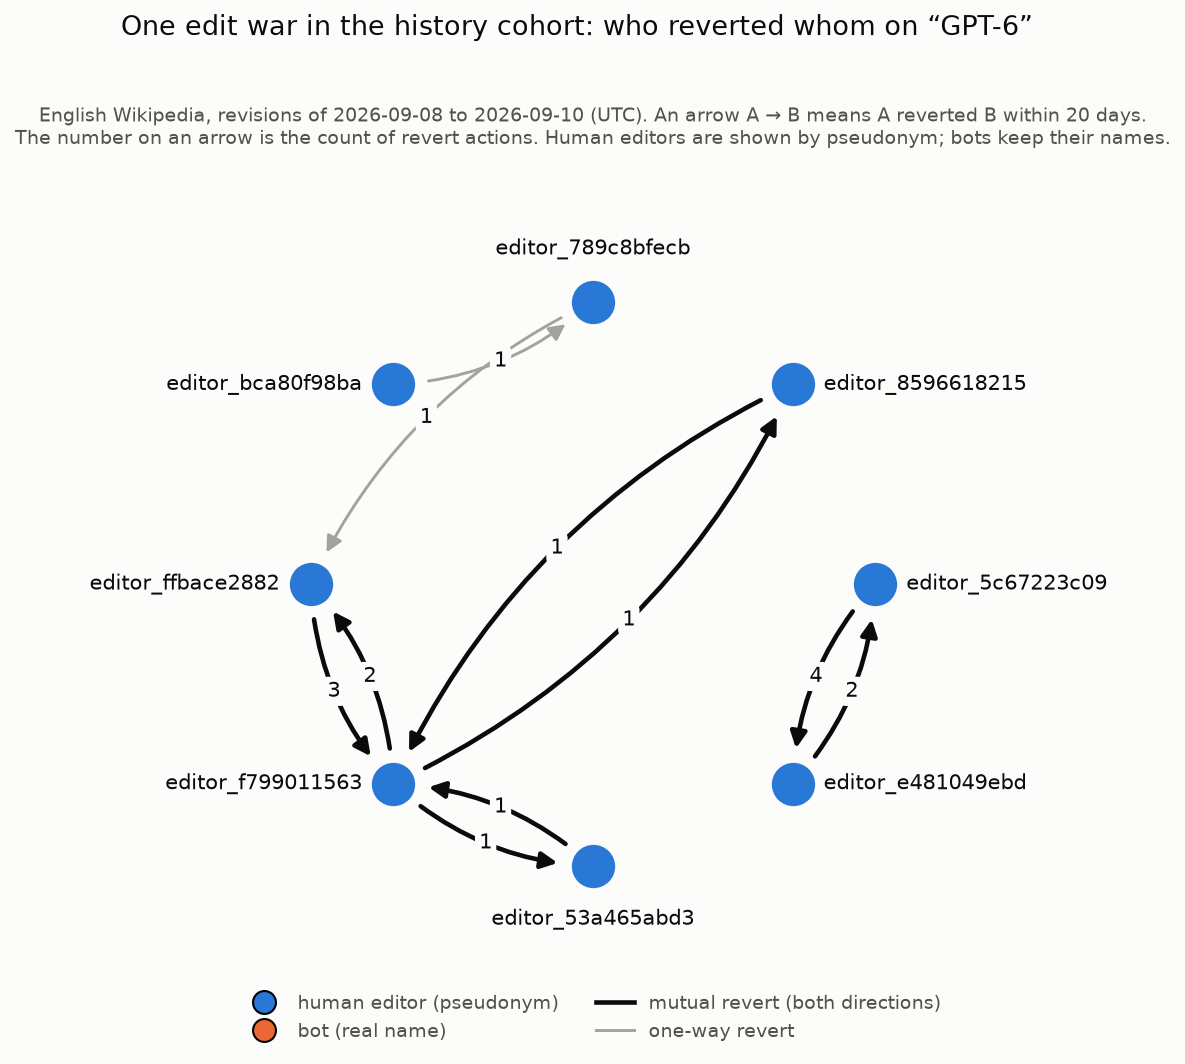

page 84135854: GPT-6
| reverter          | src_kind   | reverted          | dst_kind   |   count |
|-------------------|------------|-------------------|------------|---------|
| editor_789c8bfecb | temporary  | editor_ffbace2882 | registered |       1 |
| editor_8596618215 | registered | editor_f799011563 | registered |       1 |
| editor_bca80f98ba | registered | editor_789c8bfecb | temporary  |       1 |
| editor_ffbace2882 | registered | editor_f799011563 | registered |       3 |
| editor_5c67223c09 | registered | editor_e481049ebd | registered |       4 |
| editor_53a465abd3 | registered | editor_f799011563 | registered |       1 |
| editor_f799011563 | registered | editor_8596618215 | registered |       1 |
| editor_f799011563 | registered | editor_ffbace2882 | registered |       2 |
| editor_f799011563 | registered | editor_53a465abd3 | registered |       1 |
| editor_e481049ebd | registered | editor_5c67223c09 | registered |       2 |


In [9]:
display(Image(filename=str(config.FIGURES_DIR / "neo4j_edit_war_example.png"), width=650))
page_id = run_cypher.pick_war_page(r4["main"])
title, edges = run_cypher.war_edges(session, page_id)
print(f"page {page_id}: {title}")
show(edges[["src", "src_kind", "dst", "dst_kind", "n"]].rename(columns={"src": "reverter", "dst": "reverted", "n": "count"}))

## 9. Timings

**What:** Shows the timings: the median of 7 warm runs from `results/cypher_summary.csv`, next to the single run here.

**Why:** The Neo4j section reports query times; use the 7-run medians.

**You should see:** All main results under 0.5 s; Louvain runs once (it writes). Cypher Q1 and `compare_top_contested` are also comparison queries. Their times here are single-engine runs: for the comparison, use `cmp_ms_*` from `results/comparison.csv` (notebook 04).

In [10]:
cs = pd.read_csv(config.RESULTS_DIR / "cypher_summary.csv")
cs["this notebook, 1 run (ms)"] = [times.get((q, r)) for q, r in zip(cs["query"], cs["result"])]
show(cs)

| query                         | result          | file                                                   |   result_rows |   median_ms |   min_ms |   max_ms |   runs |   this notebook, 1 run (ms) |
|-------------------------------|-----------------|--------------------------------------------------------|---------------|-------------|----------|----------|--------|-----------------------------|
| q1_mutual_reverts             | main            | cypher_q1_mutual_reverts.csv                           |           462 |       261.2 |    228.7 |    276.5 |      7 |                       319.9 |
| q1_mutual_reverts             | total           | cypher_q1_mutual_reverts_total.csv                     |             1 |       169.1 |    157.5 |    236.4 |      7 |                       353   |
| q2_central_reverters          | main            | cypher_q2_central_reverters.csv                        |            20 |       206.1 |    166.8 |   1156.9 |      7 |                      1688.3 |


## Check against FACTS.md

**What:** Compares the key numbers of this notebook with `report/FACTS.md`. Then it checks every number in the text of this notebook (the fact markers) against FACTS.md.

**Why:** The report uses FACTS.md. If a number here is different, the data or the code changed: tell the Report+GenAI owner before you copy any number.

**You should see:** Two tables with one row per number, and the lines `OK: all ... numbers match FACTS.md` and `OK: all ... numbers in the text match FACTS.md`. `DIFFERENT` means a number changed (normal for PROVISIONAL numbers after the live refresh). Then run `report/build_facts.py` and `report/sync_notebook_text.py` again.

In [11]:
facts.check({
    "neo4j_editor_count": counts["Editor"], "neo4j_page_count": counts["Page"],
    "neo4j_edited_count": counts["EDITED"], "neo4j_reverted_count": counts["REVERTED"],
    "contested_pages_total": counts["contested Page"],
    "cypher_q1_mutual_pairs": tot["mutual_pairs"], "cypher_q1_pages": tot["pages"],
    "cypher_q1_editors": tot["editors"], "cypher_q1_pairs_with_bot": tot["pairs_with_bot"],
    "top20_mutual_pairs": len(on_top),
    "cypher_q2_top_pagerank_editor": t2["editor"], "cypher_q2_top_pagerank": t2["pagerank"],
    "cypher_q2_top_by_degree_editor": b2["editor"], "cypher_q2_top_by_degree_out_degree": b2["out_degree"],
    "cypher_q2_pagerank_fewest_reverts_editor": few["editor"],
    "cypher_q2_pagerank_fewest_reverts_made": few["reverts_made"],
    "cypher_q3_louvain_communities": r3["louvain_stats"].iloc[0]["communities"],
    "cypher_q3_largest_community_editors": c1["editors"],
    "cypher_q3_communities_2plus": cz["communities_2plus"],
    "cypher_q3_largest_community_star_share_pct": 100 * c1["star_share"],
    "cypher_q3_largest_community_top_page_share_pct": 100 * c1["top_page_reverts"] / c1["reverts"],
    "cypher_q3_largest_wcc_editors": r3["wcc_largest"].iloc[0]["editors"],
    "cypher_q4_top_page_title": t4["page_title"],
    "cypher_q4_top_page_warring_editors": t4["warring_editors"],
    "cypher_q5_top_pair_shared_pages": r5["main"].iloc[0]["shared_contested_pages"],
})
session.close(); driver.close()
print()
from report import sync_notebook_text
sync_notebook_text.check_markers(HW2 / "notebooks" / "03_neo4j.ipynb")
print(f"\nnotebook time: {time.time() - T0:.0f} s")

| key                                            | FACTS.md          | notebook          | status   | result   |
|------------------------------------------------|-------------------|-------------------|----------|----------|
| neo4j_editor_count                             | 37,546            | 37,546            | FINAL    | OK       |
| neo4j_page_count                               | 165,415           | 165,415           | FINAL    | OK       |
| neo4j_edited_count                             | 295,013           | 295,013           | FINAL    | OK       |
| neo4j_reverted_count                           | 13,269            | 13,269            | FINAL    | OK       |
| contested_pages_total                          | 126               | 126               | FINAL    | OK       |
| cypher_q1_mutual_pairs                         | 462               | 462               | FINAL    | OK       |
| cypher_q1_pages                                | 397               | 397               | FINAL

Numbers in the text of 03_neo4j.ipynb (fact markers):
| cell   | key                                            | text              | FACTS.md          | result   |
|--------|------------------------------------------------|-------------------|-------------------|----------|
| 0      | cypher_q1_mutual_pairs                         | 462               | 462               | OK       |
| 0      | cypher_q1_pages                                | 397               | 397               | OK       |
| 0      | top20_mutual_pairs                             | 51                | 51                | OK       |
| 0      | top20_mutual_pairs_pct                         | 11.04             | 11.04             | OK       |
| 0      | cypher_q2_top_by_degree_editor                 | ClueBot NG        | ClueBot NG        | OK       |
| 0      | cypher_q2_top_pagerank_editor                  | ClueBot NG        | ClueBot NG        | OK       |
| 0      | cypher_q3_communities_2plus                    